**E-Commerce Performance and Customer Experience Analysis**

**Objective**

This project analyzes Brazilian Olist E-Commerce Public Dataset with the purpose of understanding the following:

*   Sales and order performance
*   Product and category performance
*   Customer purchase behaviour
*   Delivery and logistics performance
*   Payment behaviour
*   Customer satisfaction
*   Seller performance

The project uses Python and Pandas for the data preparation, validation, and exploratory analysis. The resulting insights will be used to support further analysis in SQL, Excel and Power BI.

**Data Limitation**

The dataset does not include cost of goods sold(COGS), therefore, this project does not have any estimate of profit or profit margin.

The financial analysis is based on the available measures like:

*   Product value
*   Freight value
*   Total order value
*   Average order value
*   Payment value
*   Order volume

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**1.  Loading Data**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

data_path = '/content/drive/MyDrive/Projects/E-commerce/data/'

files = os.listdir(data_path)
files

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv',
 'archive (7).zip']

In [4]:
csv_files = [
    file for file in files if file.endswith('.csv')
]
csv_files

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

In [5]:
tables = {}

for file in csv_files:
  table_name = file.replace('.csv', '').replace('olist_', '').replace('_dataset', '')
  tables[table_name] = pd.read_csv(os.path.join(data_path, file))

tables.keys()

dict_keys(['customers', 'geolocation', 'order_items', 'order_payments', 'order_reviews', 'orders', 'products', 'sellers', 'product_category_name_translation'])

**2.  Data Structure and Data Understanding**

This dataset consists of several relational tables which include customers, sellers, geolocation, order, order item, order payment, order review, product, and product category translation.

The tables are connected primarily through identifiers such as:

*   order_id
*   customer_id
*   customer_unique_id
*   product_id
*   seller_id

In [6]:
for name, df in tables.items():
  print(f'{name}: {df.shape}')

customers: (99441, 5)
geolocation: (1000163, 5)
order_items: (112650, 7)
order_payments: (103886, 5)
order_reviews: (99224, 7)
orders: (99441, 8)
products: (32951, 9)
sellers: (3095, 4)
product_category_name_translation: (71, 2)


In [7]:
for name, df in tables.items():
  print(f'\n{name}')
  print(df.columns.to_list())


customers
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

geolocation
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

order_items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

order_payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

order_reviews
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

products
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_heigh

In [65]:
data_dictionary = []

for table_name, df in tables.items():
  for column in df.columns:

    data_dictionary.append({
        'table': table_name,
        'column': column,
        'data_type': str(df[column].dtype),
        'missing_value': df[column].isna().sum(),
        'unique_value': df[column].nunique()
    })

data_dictionary = pd.DataFrame(data_dictionary)
data_dictionary

,table,column,data_type,missing_value,unique_value
0,customers,customer_id,object,0,99441
1,customers,customer_unique_id,object,0,96096
2,customers,customer_zip_code_prefix,string,0,14994
3,customers,customer_city,object,0,4119
4,customers,customer_state,object,0,27
5,geolocation,geolocation_zip_code_prefix,string,0,19015
6,geolocation,geolocation_lat,float64,0,717360
7,geolocation,geolocation_lng,float64,0,717613
8,geolocation,geolocation_city,object,0,8011
9,geolocation,geolocation_state,object,0,27


**3. Data Quality & Preparation**

Before analysis, the dataset was checked for:

* Duplicate keys
* Referential integrity
* Missing values
* Numeric values outside expected ranges.
* Invalid review scores
* Date parsing problems
* Chronological inconsistencies
* Product metadata completeness
* Payment anomalies
* Product dimension and weight anomalies

Unusual records were not automatically deleted. In cases where the validity of a record could not be established, the original value was retained and an indicator flag was created.

In [66]:
print('Orders:', tables['orders']['order_id'].nunique())
print('Customers:', tables['customers']['customer_id'].nunique())
print('Unique customers:', tables['customers']['customer_unique_id'].nunique())
print('Order rows:', len(tables['orders']))
print('Customer rows:', len(tables['customers']))

Orders: 99441
Customers: 99441
Unique customers: 96096
Order rows: 99441
Customer rows: 99441


In [10]:
order_items = tables['order_items']

print('Order item rows:', len(order_items))
print('Unique orders:', order_items['order_id'].nunique())
print('Unique products:', order_items['product_id'].nunique())
print('Unique sellers:', order_items['seller_id'].nunique())

Order item rows: 112650
Unique orders: 98666
Unique products: 32951
Unique sellers: 3095


In [11]:
items_per_order = order_items.groupby('order_id').size()
items_per_order.describe()

,0
count,98666.000000
mean,1.141731
std,0.538452
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,21.000000


In [12]:
order_customer_check = tables['orders']['customer_id'].isin(tables['customers']['customer_id'])
print('Valid_order_customer_reference:', order_customer_check.sum())
print('Invalid_order_customer_reference:', (~order_customer_check).sum())

product_check = tables['products']['product_id'].isin(tables['order_items']['product_id'])
print('Valid_product_reference:', product_check.sum())
print('Invalid_product_reference:', (~product_check).sum())

sellers_check = tables['sellers']['seller_id'].isin(tables['order_items']['seller_id'])
print('Valid_sellers_reference:', sellers_check.sum())
print('Invalid_sellers_reference:', (~sellers_check).sum())

orders_check = tables['orders']['order_id'].isin(tables['order_items']['order_id'])
print('Valid_orders_reference:', orders_check.sum())
print('Invalid_orders_reference:', (~orders_check).sum())

Valid_order_customer_reference: 99441
Invalid_order_customer_reference: 0
Valid_product_reference: 32951
Invalid_product_reference: 0
Valid_sellers_reference: 3095
Invalid_sellers_reference: 0
Valid_orders_reference: 98666
Invalid_orders_reference: 775


In [13]:
missing_values = []

for name, df in tables.items():
  for column in df.columns:
    missing = df[column].isna().sum()
    total = len(df)

    missing_values.append({
        "table_name": name,
        'column': column,
        'missing': missing,
        '%_missing': (missing/total) * 100
    })

missing_df = pd.DataFrame(missing_values)

missing_df = missing_df[missing_df['missing']>0].sort_values('%_missing', ascending=False)
missing_df

,table_name,column,missing,%_missing
25,order_reviews,review_comment_title,87656,88.341530
26,order_reviews,review_comment_message,58247,58.702532
35,orders,order_delivered_customer_date,2965,2.981668
39,products,product_name_lenght,610,1.851234
38,products,product_category_name,610,1.851234
40,products,product_description_lenght,610,1.851234
41,products,product_photos_qty,610,1.851234
34,orders,order_delivered_carrier_date,1783,1.793023
33,orders,order_approved_at,160,0.160899
42,products,product_weight_g,2,0.006070


In [14]:
orders_missing_dates = pd.DataFrame({
    'column': ['order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date'],
    'missing': [tables['orders']['order_approved_at'].isna().sum(),
        tables['orders']['order_delivered_carrier_date'].isna().sum(),
        tables['orders']['order_delivered_customer_date'].isna().sum()]
})

orders_missing_dates

,column,missing
0,order_approved_at,160
1,order_delivered_carrier_date,1783
2,order_delivered_customer_date,2965


In [15]:
delivered_order_status = tables['orders'].loc[
    tables['orders']['order_delivered_customer_date'].isna(), 'order_status'
].value_counts()

delivered_order_status

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


In [16]:
approved_order_status = tables['orders'].loc[
    tables['orders']['order_approved_at'].isna(), 'order_status'].value_counts()

approved_order_status

,count
order_status,
canceled,141
delivered,14
created,5


In [17]:
products = tables['products'].copy()

incomplete_data_columns = ['product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty']

products['missing_info'] = products[incomplete_data_columns].isna().any(axis=1)
product_with_missing_info = products[products['missing_info']]

print('products with incomplete data: ', product_with_missing_info['product_id'].nunique())

missing_info_items = order_items[order_items['product_id'].isin(product_with_missing_info['product_id'])]

print('Order items affected: ', len(missing_info_items))
print('Unique orders affected: ', missing_info_items['order_id'].nunique())

products with incomplete data:  610
Order items affected:  1603
Unique orders affected:  1451


In [18]:
missing_sales = missing_info_items['price'].sum()
total_sales = tables['order_items']['price'].sum()
pct_missing = (missing_sales / total_sales) * 100

print('missing product sales: ', missing_sales)
print('total sales price: ', total_sales)
print(f'%missing_product_price: {pct_missing:.2f}%')

missing product sales:  179535.28
total sales price:  13591643.700000003
%missing_product_price: 1.32%


In [19]:
duplicate_checks = {
    'orders_order_id' : tables['orders']['order_id'].duplicated().sum(),
    'customers_customer_id' :tables['customers']['customer_id'].duplicated().sum(),
    'products_product_id' : tables['products']['product_id'].duplicated().sum(),
    'sellers_seller_id' : tables['sellers']['seller_id'].duplicated().sum(),
    'order_item(order_id, order_item_id)' : tables['order_items'].duplicated(['order_id', 'order_item_id']).sum(),
    'order_review(order_id, review_id)' : tables['order_reviews'].duplicated(['order_id', 'review_id']).sum(),
    'order_payment(order_id, payment_sequential)' : tables['order_payments'].duplicated(['order_id','payment_sequential']).sum()
}

for key, duplicates in duplicate_checks.items():
  print(f'{key}: {duplicates} duplicates')

orders_order_id: 0 duplicates
customers_customer_id: 0 duplicates
products_product_id: 0 duplicates
sellers_seller_id: 0 duplicates
order_item(order_id, order_item_id): 0 duplicates
order_review(order_id, review_id): 0 duplicates
order_payment(order_id, payment_sequential): 0 duplicates


In [20]:
print("Duplicate order_id in reviews:",tables['order_reviews']['order_id'].duplicated().sum())
print("Unique orders in reviews:",tables['order_reviews']['order_id'].nunique())
print("Review rows:",len(tables['order_reviews']))

Duplicate order_id in reviews: 551
Unique orders in reviews: 98673
Review rows: 99224


In [21]:
reviews_per_order = (tables['order_reviews'].groupby('order_id').size())
reviews_per_order.value_counts().sort_index()

,count
1,98126
2,543
3,4


In [23]:
print('Review_score', tables['order_reviews']['review_score'].value_counts().sort_index())
print('Invalid_review_score:', (~tables['order_reviews']['review_score'].between(1,5)).sum())

Review_score review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Invalid_review_score: 0


In [24]:
money_cols = {
    'order_items': ['price', 'freight_value'], 'order_payments': ['payment_value']
}

for table, cols in money_cols.items():
  print(f'\n{'='*50}')
  print(f'{table.upper()}')
  print(f'{'='*50}')

  for col in cols:
    print(f'\n{col}')
    print('minimum:', tables[table][col].min())
    print('maximum:', tables[table][col].max())
    print('zero:', (tables[table][col]==0).sum())
    print('negative:', (tables[table][col] < 0).sum())


ORDER_ITEMS

price
minimum: 0.85
maximum: 6735.0
zero: 0
negative: 0

freight_value
minimum: 0.0
maximum: 409.68
zero: 383
negative: 0

ORDER_PAYMENTS

payment_value
minimum: 0.0
maximum: 13664.08
zero: 9
negative: 0


In [25]:
print(f'Order_payment')
print('minimum:', tables['order_payments']['payment_installments'].min())
print('maximum:', tables['order_payments']['payment_installments'].max())
print('zero:', (tables['order_payments']['payment_installments']==0).sum())
print('negative:', (tables['order_payments']['payment_installments']< 0).sum())

Order_payment
minimum: 0
maximum: 24
zero: 2
negative: 0


In [26]:
product_measurements = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

for col in product_measurements:
  print(f'{col}:')
  print('minimum:', tables['products'][col].min())
  print('maximum:', tables['products'][col].max())
  print('zero:', (tables['products'][col]==0).sum())
  print('negative:', (tables['products'][col] < 0).sum())

product_weight_g:
minimum: 0.0
maximum: 40425.0
zero: 4
negative: 0
product_length_cm:
minimum: 7.0
maximum: 105.0
zero: 0
negative: 0
product_height_cm:
minimum: 2.0
maximum: 105.0
zero: 0
negative: 0
product_width_cm:
minimum: 6.0
maximum: 118.0
zero: 0
negative: 0


In [22]:
datetime_cols = {'orders': ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                            'order_delivered_customer_date', 'order_estimated_delivery_date'],
                 'order_items': ['shipping_limit_date'],
                 'order_reviews': ['review_creation_date', 'review_answer_timestamp']
}

for table, cols in datetime_cols.items():
  print(f'\n{'='*50}')
  print(f'{table.upper()}')
  print(f'{'='*50}')

  for col in cols:
    dates = pd.to_datetime(tables[table][col], errors='coerce')
    non_null = (tables[table][col].notna() & dates.isna()).sum()

    print(f'{col} has {non_null} not_dates values')

for table, col in zip_cols.items():
  print(f'\n {table} zip_prefix')
  print('min:', tables[table][col].min())
  print('max:', tables[table][col].max())
  print('unique:', tables[table][col].nunique())


ORDERS
order_purchase_timestamp has 0 not_dates values
order_approved_at has 0 not_dates values
order_delivered_carrier_date has 0 not_dates values
order_delivered_customer_date has 0 not_dates values
order_estimated_delivery_date has 0 not_dates values

ORDER_ITEMS
shipping_limit_date has 0 not_dates values

ORDER_REVIEWS
review_creation_date has 0 not_dates values
review_answer_timestamp has 0 not_dates values

 customers zip_prefix
min: 1003
max: 99990
unique: 14994

 geolocation zip_prefix
min: 1001
max: 99990
unique: 19015

 sellers zip_prefix
min: 1001
max: 99730
unique: 2246


In [27]:
date_cols = {'orders': ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
                            'order_delivered_customer_date', 'order_estimated_delivery_date'],
    'order_items': ['shipping_limit_date'],
    'order_reviews': ['review_creation_date', 'review_answer_timestamp']
}

for table, cols in date_cols.items():
  for col in cols:
    tables[table][col] = pd.to_datetime(tables[table][col], errors='coerce')

for table, cols in date_cols.items():
  print(f'\n{'='*20} {table.upper()} {'='*20}')
  for col in cols:
    print(col, tables[table][col].dtype)


==================== ORDERS ====================
order_purchase_timestamp datetime64[ns]
order_approved_at datetime64[ns]
order_delivered_carrier_date datetime64[ns]
order_delivered_customer_date datetime64[ns]
order_estimated_delivery_date datetime64[ns]

==================== ORDER_ITEMS ====================
shipping_limit_date datetime64[ns]

==================== ORDER_REVIEWS ====================
review_creation_date datetime64[ns]
review_answer_timestamp datetime64[ns]


In [67]:
orders = tables['orders']

print('approval_before_purcahsed:', (orders['order_approved_at'] < orders['order_purchase_timestamp']).sum())
print('carrier_delivery_before_purcahsed:', (orders['order_delivered_carrier_date'] < orders['order_purchase_timestamp']).sum())
print('customer_delivery_before_purcahsed:', (orders['order_delivered_customer_date'] < orders['order_purchase_timestamp']).sum())
print('estimated_delivery_before_purcahsed:', (orders['order_estimated_delivery_date'] < orders['order_purchase_timestamp']).sum())

print('Customer delivered before carrier:',(orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date']).sum())

approval_before_purcahsed: 0
carrier_delivery_before_purcahsed: 166
customer_delivery_before_purcahsed: 0
estimated_delivery_before_purcahsed: 0
Customer delivered before carrier: 23


In [29]:
item_dates = tables['order_items'][['order_id', 'shipping_limit_date']].copy()

item_dates = item_dates.merge(tables['orders'][['order_id', 'order_purchase_timestamp']], on='order_id', how='left')

print('shipping_limit_before_purchase:', (item_dates['shipping_limit_date'] < item_dates['order_purchase_timestamp']).sum())

shipping_limit_before_purchase: 0


In [68]:
payments = tables['order_payments']
products = tables['products']
orders = tables['orders']

orders['carrier_before_purchase_flag'] = (orders['order_delivered_carrier_date'].notna() &
            orders['order_purchase_timestamp'].notna() & (orders['order_delivered_carrier_date']
            < orders['order_purchase_timestamp']))

orders['customer_before_carrier_flag'] = (orders['order_delivered_customer_date'].notna() &
            orders['order_delivered_carrier_date'].notna() &(orders['order_delivered_customer_date']
            < orders['order_delivered_carrier_date']))

payments['zero_payment_flag'] = (payments['payment_value'] == 0)

payments['zero_installment_flag'] = (payments['payment_installments'] == 0)

products['zero_weight_flag'] = (products['product_weight_g'] == 0)

print("Carrier before purchase:", orders['carrier_before_purchase_flag'].sum())
print("Customer before carrier:", orders['customer_before_carrier_flag'].sum())
print("Zero payments:", payments['zero_payment_flag'].sum())
print("Zero installments:", payments['zero_installment_flag'].sum())
print("Zero-weight products:", products['zero_weight_flag'].sum())

Carrier before purchase: 166
Customer before carrier: 23
Zero payments: 9
Zero installments: 2
Zero-weight products: 4


**4.  Sales and Order Performance**


This section investigates the order volume, freight value, product value, and total order value.

This dataset does not contain cost information, therefore, total order value was calculated using product value and freight value instead of profit based measure.

In [69]:
order_values = tables['order_items'].groupby('order_id').agg(
    product_value = ('price', 'sum'), freight_value = ('freight_value','sum'),
    item_count = ('order_item_id', 'count')
).reset_index()

order_values['total_order_value'] = order_values['product_value'] + order_values['freight_value']
order_values.head()

,order_id,product_value,freight_value,item_count,total_order_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,72.19
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,259.83
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,216.87
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,218.04


In [34]:
order_analysis = tables['orders'].merge(order_values, on='order_id', how='left').merge(
     tables['customers'][['customer_id', 'customer_unique_id', 'customer_state']])
order_analysis.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,carrier_before_purchase_flag,customer_before_carrier_flag,product_value,freight_value,item_count,total_order_value,customer_unique_id,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,29.99,8.72,1.0,38.71,7c396fd4830fd04220f754e42b4e5bff,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,118.70,22.76,1.0,141.46,af07308b275d755c9edb36a90c618231,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,159.90,19.22,1.0,179.12,3a653a41f6f9fc3d2a113cf8398680e8,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,45.00,27.20,1.0,72.20,7c142cf63193a1473d2e66489a9ae977,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,19.90,8.72,1.0,28.62,72632f0f9dd73dfee390c9b22eb56dd6,SP


In [35]:
order_analysis['delivery_days'] = (order_analysis['order_delivered_customer_date'] -
                                   order_analysis['order_purchase_timestamp']).dt.total_seconds()/(24*60*60)

order_analysis['est_delivery_days'] = (order_analysis['order_estimated_delivery_date'] -
                                       order_analysis['order_purchase_timestamp']).dt.total_seconds()/(24*60*60)

order_analysis['delivered_delayed_days'] = order_analysis['delivery_days'] - order_analysis['est_delivery_days']

delivered_orders = order_analysis[order_analysis['order_status'] == 'delivered'].copy()
delivered_orders['is_late'] = (delivered_orders['order_delivered_customer_date'].notna() &
                              delivered_orders['order_estimated_delivery_date'].notna() &
                              (delivered_orders['order_delivered_customer_date'] > delivered_orders['order_estimated_delivery_date']))

average_delivery_days = delivered_orders['delivery_days'].mean()
median_delivery_days = delivered_orders['delivery_days'].median()

late_delivery_rate = delivered_orders['is_late'].mean() * 100
print(f'average_delivery_days: {average_delivery_days:.2f}days')
print(f'median_delivery_days: {median_delivery_days:.2f}days')
print(f'late_delivery_rate: {late_delivery_rate:.2f}%')

average_delivery_days: 12.56days
median_delivery_days: 10.22days
late_delivery_rate: 8.11%


In [36]:
delivered_orders['delivery_performance'] = np.select(
    [delivered_orders['order_delivered_customer_date'].isna(),
     delivered_orders['order_estimated_delivery_date'].isna(),
     delivered_orders['order_delivered_customer_date'] < delivered_orders['order_estimated_delivery_date'],
     delivered_orders['order_delivered_customer_date'] == delivered_orders['order_estimated_delivery_date'],
     delivered_orders['order_delivered_customer_date'] > delivered_orders['order_estimated_delivery_date']
     ],
      ['Unknown', 'Unknown', 'Early', 'On Time', 'Late'], default= 'Unknown')
delivery_performance = delivered_orders['delivery_performance'].value_counts().reset_index()
delivery_performance

,delivery_performance,count
0,Early,88644
1,Late,7826
2,Unknown,8


In [37]:
order_analysis['order_year'] = order_analysis['order_purchase_timestamp'].dt.year
order_analysis['order_month'] = order_analysis['order_purchase_timestamp'].dt.month
order_analysis['order_month_name'] = order_analysis['order_purchase_timestamp'].dt.month_name()
order_analysis['order_date'] = order_analysis['order_purchase_timestamp'].dt.date
order_analysis['order_year_month'] = order_analysis['order_purchase_timestamp'].dt.to_period('M').astype(str)

In [70]:
total_orders = order_analysis['order_id'].nunique()

orders_with_items = order_analysis['total_order_value'].notna().sum()

total_product_value = order_analysis['product_value'].sum()
total_freight_value = order_analysis['freight_value'].sum()
total_order_value = order_analysis['total_order_value'].sum()

average_order_value = order_analysis['total_order_value'].mean()

print(f'Total orders: {total_orders:,}')
print(f'Orders with item records: {orders_with_items:,}')
print(f'Total product value: {total_product_value:,.2f}')
print(f'Total freight value: {total_freight_value:,.2f}')
print(f'Total order value: {total_order_value:,.2f}')
print(f'Average order value: {average_order_value:,.2f}')

Total orders: 99,441
Orders with item records: 98,666
Total product value: 13,591,643.70
Total freight value: 2,251,909.54
Total order value: 15,843,553.24
Average order value: 160.58


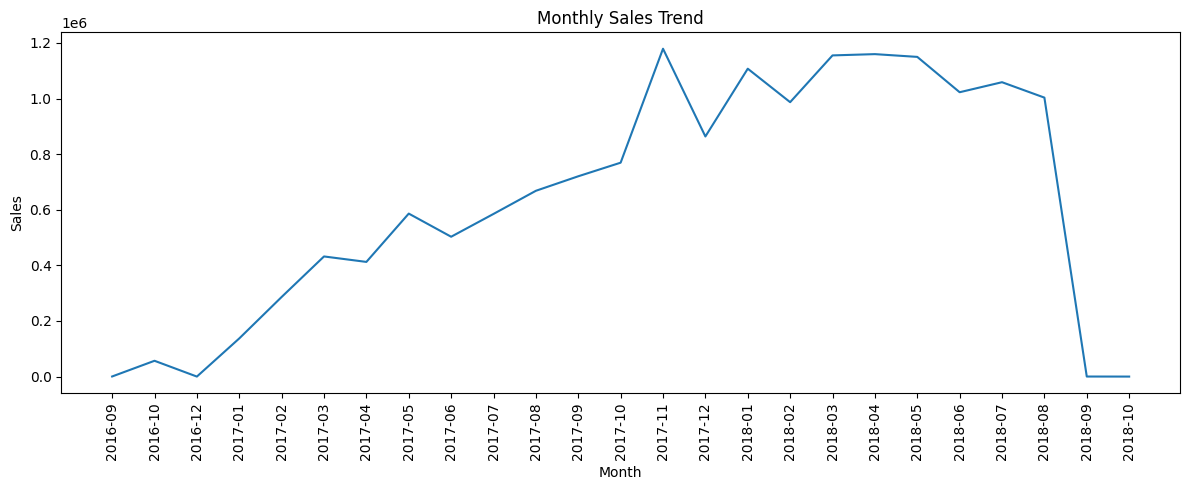

In [39]:
monthly_sales = order_analysis.groupby('order_year_month').agg(
    orders = ('order_id', 'nunique'), sales= ('total_order_value', 'sum')
).reset_index()

plt.figure(figsize=(12,5))
plt.plot(monthly_sales['order_year_month'], monthly_sales['sales'])

plt.xticks(rotation=90)
plt.xlabel('Month')
plt.ylabel('Sales')
plt.title('Monthly Sales Trend')

plt.tight_layout()
plt.show()

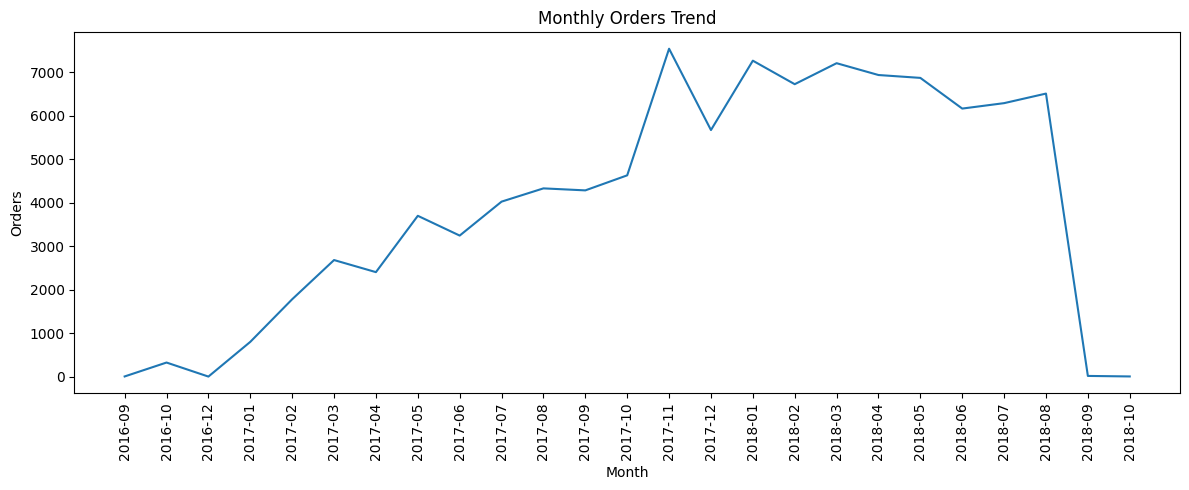

In [40]:
plt.figure(figsize=(12,5))
plt.plot(monthly_sales['order_year_month'], monthly_sales['orders'])

plt.xticks(rotation=90)
plt.xlabel('Month')
plt.ylabel('Orders')
plt.title('Monthly Orders Trend')

plt.tight_layout()
plt.show()

In [41]:
order_status = order_analysis['order_status'].value_counts().reset_index()
order_status

,order_status,count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


**5.  Product and Category Performance**

This section evaluates the product categories and individual products using product value, items sold and average price.

The English product-category translations, are provided with the available translation and the two categories without translation in the translation table are explicitly mapped and not dropped.

In [42]:
product_category = set(tables['products']['product_category_name'].dropna().unique())
translation_category = set(tables['product_category_name_translation']['product_category_name'].unique())
translation_not_included = product_category - translation_category
print(len(translation_not_included))
print('translation_not_included:', translation_not_included)

print(tables['products'][tables['products']['product_category_name'].isin(translation_not_included)])

2
translation_not_included: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}
                             product_id  \
1628   0105b5323d24fc655f73052694dbbb3a   
5821   6fd83eb3e0799b775e4f946bd66657c0   
7325   5d923ead886c44b86845f69e50520c3e   
7478   6727051471a0fc4a0e7737b57bff2549   
8819   bed164d9d628cf0593003389c535c6e0   
11039  1220978a08a6b29a202bc015b18250e9   
14266  ae62bb0f95af63d64eae5f93dddea8d3   
16182  1954739d84629e7323a4295812a3e0ec   
16930  dbe520fb381ad695a7e1f2807d20c765   
17800  c7a3f1a7f9eef146cc499368b578b884   
18610  7afdd65f79f63819ff5bee328843fa37   
26890  a4756663d007b0cd1af865754d08d968   
29919  cb9d764f38ee4d0c00af64d5c388f837   

                               product_category_name  product_name_lenght  \
1628                                        pc_gamer                 59.0   
5821   portateis_cozinha_e_preparadores_de_alimentos                 52.0   
7325   portateis_cozinha_e_preparadores_de_alimentos                 58.0   

In [71]:
missing_product_translation = {'pc_gamer': 'Gaming PC', 'portateis_cozinha_e_preparadores_de_alimentos':
        'Kitchen & Food Preparation Appliances'}

product_analysis = products.merge(tables['product_category_name_translation'],
    on='product_category_name', how='left', validate='many_to_one')

product_analysis['product_category_name_english'] = (product_analysis['product_category_name_english']
    .fillna(product_analysis['product_category_name'].map(missing_product_translation))
    .fillna('Unknown / Incomplete Metadata'))

print('Products with no reporting category:', product_analysis['product_category_name_english'].isna().sum())

product_analysis[['product_id', 'product_category_name',
     'product_category_name_english', 'product_info_missing']].head()

Products with no reporting category: 0


,product_id,product_category_name,product_category_name_english,product_info_missing
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,False
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,False
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,False
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,False
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,False


In [73]:
item_product = tables['order_items'].merge(product_analysis[['product_id', 'product_category_name_english']],
                                           on= 'product_id', how= 'left')

category_sales = item_product.groupby('product_category_name_english').agg(
    product_value = ('price', 'sum'), items_sold = ('order_item_id', 'count'), average_item_price = ('price', 'mean')
).reset_index()

category_sales = category_sales.sort_values('product_value', ascending=False)
category_sales

,product_category_name_english,product_value,items_sold,average_item_price
46,health_beauty,1258681.34,9670,130.163531
73,watches_gifts,1205005.68,5991,201.135984
10,bed_bath_table,1036988.68,11115,93.296327
68,sports_leisure,988048.97,8641,114.344285
18,computers_accessories,911954.32,7827,116.513903
...,...,...,...,...
38,flowers,1110.04,33,33.637576
49,home_comfort_2,760.27,30,25.342333
14,cds_dvds_musicals,730.00,14,52.142857
32,fashion_childrens_clothes,569.85,8,71.231250


In [74]:
product_sales = item_product.groupby(['product_id', 'product_category_name_english']).agg(
    product_value = ('price', 'sum'), items_sold = ('order_item_id', 'count'), average_item_price = ('price', 'mean'),
).reset_index()

product_sales = product_sales.sort_values('product_value', ascending=False)
product_sales.head(10)

,product_id,product_category_name_english,product_value,items_sold,average_item_price
24086,bb50f2e236e5eea0100680137654686c,health_beauty,63885.00,195,327.615385
14068,6cdd53843498f92890544667809f1595,health_beauty,54730.20,156,350.834615
27613,d6160fb7873f184099d9bc95e30376af,computers,48899.34,35,1397.124000
27039,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,47214.51,343,137.651633
19742,99a4788cb24856965c36a24e339b6058,bed_bath_table,43025.56,488,88.167131
8051,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,41082.60,274,149.936496
4996,25c38557cf793876c5abdd5931f922db,baby,38907.32,38,1023.876842
12351,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,37733.90,63,598.950794
10867,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,37683.42,323,116.666935
22112,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,37608.90,527,71.364137


**6.  Customer Behaviour Analysis**

Customer - level analysis examines customer value, repeat purchasing, customer frequency, and geographic distribution.

This analysis uses 'customer_unique_id' because 'customer_id' identifies customer-order records rather than underlying customer

In [75]:
orders_per_customer = order_analysis.groupby('customer_unique_id').agg(
    order_count=('order_id', 'nunique'), total_order_value = ('total_order_value', 'sum')
).reset_index()

orders_per_customer.head()

,customer_unique_id,order_count,total_order_value
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19
2,0000f46a3911fa3c0805444483337064,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,1,196.89


In [47]:
repeat_customers = (orders_per_customer['order_count'] > 1).sum()
unique_customers = (orders_per_customer['customer_unique_id'].nunique())
repeat_customer_rate = (repeat_customers / len(orders_per_customer) * 100)

print('Unique customers: ', unique_customers)
print('Repeat customers: ', repeat_customers)
print('Repeat customer rate: ', repeat_customer_rate)

Unique customers:  96096
Repeat customers:  2997
Repeat customer rate:  3.1187562437562435


In [48]:
orders_per_customer['order_count'].describe()

,order_count
count,96096.000000
mean,1.034809
std,0.214384
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,17.000000


In [49]:
purchase_frequency = (orders_per_customer['order_count'].value_counts().sort_index())
purchase_frequency

,count
order_count,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


In [76]:
top_customers = orders_per_customer.sort_values('total_order_value', ascending=False).head(10)
top_customers

,customer_unique_id,order_count,total_order_value
3826,0a0a92112bd4c708ca5fde585afaa872,1,13664.08
81962,da122df9eeddfedc1dc1f5349a1a690c,2,7571.63
44447,763c8b1c9c68a0229c42c9fc6f662b93,1,7274.88
82808,dc4802a71eae9be1dd28f5d788ceb526,1,6929.31
26205,459bef486812aa25204be022145caa62,1,6922.21
95806,ff4159b92c40ebe40454e3e6a7c35ed6,1,6726.66
24121,4007669dec559734d6f53e029e360987,1,6081.54
35070,5d0a2980b292d049061542014e8960bf,1,4809.44
89688,eebb5dda148d3893cdaf5b5ca3040ccb,1,4764.34
27441,48e1ac109decbb87765a3eade6854098,1,4681.78


In [51]:
customer_state_summary = (order_analysis.groupby('customer_state').agg(
        customers=('customer_unique_id', 'nunique'),
        orders=('order_id', 'nunique'),
        total_order_value=('total_order_value', 'sum')
    ).reset_index().sort_values('customers', ascending=False)
)

customer_state_summary.head(10)

,customer_state,customers,orders,total_order_value
25,SP,40302,41746,5921678.12
18,RJ,12384,12852,2129681.98
10,MG,11259,11635,1856161.49
22,RS,5277,5466,885826.76
17,PR,4882,5045,800935.44
23,SC,3534,3637,610213.60
4,BA,3277,3380,611506.67
6,DF,2075,2140,353229.44
7,ES,1964,2033,324801.91
8,GO,1952,2020,347706.93


**7.  Payment Behaviour**

This section investigates payment methods, payment values, and installment behaviour.

Zero payments and zero installments identified are flagged rather than deleted.

In [52]:
payment_method = tables['order_payments']['payment_type'].value_counts().reset_index()
payment_method['percentage'] = (payment_method['count'] / payment_method['count'].sum()* 100)

payment_method

,payment_type,count,percentage
0,credit_card,76795,73.922376
1,boleto,19784,19.043952
2,voucher,5775,5.558978
3,debit_card,1529,1.471806
4,not_defined,3,0.002888


In [53]:
payment_summary = tables['order_payments'].groupby('payment_type').agg(
    payment_records=('order_id', 'count'), total_payment_value=('payment_value', 'sum'),
    average_payment_value=('payment_value', 'mean')).reset_index()

payment_summary

,payment_type,payment_records,total_payment_value,average_payment_value
0,boleto,19784,2869361.27,145.034435
1,credit_card,76795,12542084.19,163.319021
2,debit_card,1529,217989.79,142.570170
3,not_defined,3,0.00,0.000000
4,voucher,5775,379436.87,65.703354


In [54]:
installment_distribution = (tables['order_payments'].groupby('payment_installments')
                            .size().reset_index().sort_values('payment_installments'))
installment_distribution

,payment_installments,0
0,0,2
1,1,52546
2,2,12413
3,3,10461
4,4,7098
5,5,5239
6,6,3920
7,7,1626
8,8,4268
9,9,644


**8.  State Delivery and Customer Experience**

This section evaluates delivery duration, delivery performance, and customer review.

Review data is aggregated to the order level before being joined to delivery information because some orders have multiple review records.

In [55]:
state_delivery = delivered_orders.groupby('customer_state').agg(
    orders=('order_id', 'nunique'),
    average_delivery_days=('delivery_days', 'mean'),
    median_delivery_days=('delivery_days', 'median'),
    late_rate=('is_late', 'mean')
).reset_index()

state_delivery['late_rate'] *= 100
state_delivery.sort_values('late_rate')

,customer_state,orders,average_delivery_days,median_delivery_days,late_rate
20,RO,243,19.372037,17.582361,2.880658
0,AC,80,21.035713,18.356528,3.750000
2,AM,145,26.425991,25.875139,4.137931
3,AP,67,27.185068,24.347025,4.477612
17,PR,4923,11.991582,10.425509,4.996953
10,MG,11354,12.008666,10.313513,5.610358
25,SP,40501,8.761386,7.210272,5.893682
12,MT,886,18.055756,16.109051,6.772009
6,DF,2080,12.967568,11.364925,7.067308
22,RS,5345,15.300276,13.177488,7.146866


In [56]:
review_analysis = tables['order_reviews']['review_score'].value_counts().reset_index()
review_analysis['percentage'] = review_analysis['count'] / review_analysis['count'].sum()*100
review_analysis

,review_score,count,percentage
0,5,57328,57.776344
1,4,19142,19.291704
2,1,11424,11.513344
3,3,8179,8.242965
4,2,3151,3.175643


In [57]:
average_review_score = tables['order_reviews']['review_score'].mean()
print(f'{average_review_score:.2f}')

4.09


In [58]:
order_review_score = (tables['order_reviews'].groupby('order_id').agg(average_review_score=('review_score', 'mean'),
                    review_count=('review_score', 'count')).reset_index())

In [59]:
delivery_review = delivered_orders[['order_id', 'delivery_performance', 'delivery_days', 'is_late']].merge(
    order_review_score, on='order_id', how='inner'
)

delivery_review_summary = delivery_review.groupby('delivery_performance').agg(
    orders=('order_id', 'nunique'), average_review_score=('average_review_score', 'mean')
).reset_index()
delivery_review_summary

,delivery_performance,orders,average_review_score
0,Early,88163,4.294292
1,Late,7661,2.566506
2,Unknown,8,4.500000


**9.  Seller Performance**

Seller performance is evaluated using product value. Items sold and order count are retained as support measures, while freight value is excluded as it represents shipping value, not merchandise shipping value.

In [60]:
seller_sales = order_items.groupby('seller_id').agg(
    product_value = ('price', 'sum'),items_sold = ('order_item_id', 'count'),
    orders = ('order_id', 'nunique'), average_item_price = ('price', 'mean'),
).reset_index()

seller_sales = seller_sales.merge(tables['sellers'][['seller_id', 'seller_city', 'seller_state']],
                                  on='seller_id', how='left')
seller_sales.head()

,seller_id,product_value,items_sold,orders,average_item_price,seller_city,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,2685.00,3,3,895.000000,santo andre,SP
1,001cca7ae9ae17fb1caed9dfb1094831,25080.03,239,200,104.937364,cariacica,ES
2,001e6ad469a905060d959994f1b41e4f,250.00,1,1,250.000000,sao goncalo,RJ
3,002100f778ceb8431b7a1020ff7ab48f,1234.50,55,51,22.445455,franca,SP
4,003554e2dce176b5555353e4f3555ac8,120.00,1,1,120.000000,goiania,GO


In [61]:
top_sellers = seller_sales.sort_values('product_value', ascending=False).head(10)
top_sellers

,seller_id,product_value,items_sold,orders,average_item_price,seller_city,seller_state
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1156,1132,198.505735,guariba,SP
1013,53243585a1d6dc2643021fd1853d8905,222776.05,410,358,543.356220,lauro de freitas,BA
881,4a3ca9315b744ce9f8e9374361493884,200472.92,1987,1806,100.892260,ibitinga,SP
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,586,585,331.129744,sumare,SP
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,1364,982,137.774113,itaquaquecetuba,SP
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,340,336,518.917265,barueri,SP
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1551,1314,103.311779,piracicaba,SP
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1171,1160,121.046567,sao paulo,SP
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,1428,915,97.316912,sao paulo,SP
1824,955fee9216a65b617aa5c0531780ce60,135171.70,1499,1287,90.174583,sao paulo,SP


In [62]:
total_seller_value = seller_sales['product_value'].sum()

top_10_seller_value = seller_sales.nlargest(10, 'product_value')['product_value'].sum()

top_10_sellers_rate = (top_10_seller_value / total_seller_value) * 100

print(f'Total seller value: {total_seller_value:.2f}')
print(f'Top 10 product value: {top_10_seller_value:.2f}')
print(f'Top 10 sellers rate: {top_10_sellers_rate:.2f}%')

Total seller value: 13591643.70
Top 10 product value: 1787241.74
Top 10 sellers rate: 13.15%


**10. Key Findings**

**Sales & Orders**

* 99,441 orders were recorded.
* Total product value was approximately 13.59 million.
* Total freight value was approximately 2.25 million.
* Total order value was approximately 15.84 million.
* Average order value was approximately 159.33.

**Customers**

* The dataset contains approximately 96,096 unique customers.
* 2,997 customers placed more than one order.
* The repeat-customer rate was approximately 3.12%.

**Delivery**

* The average delivery time was approximately 12.56 days.
* Median delivery time was approximately 10.22 days.
* Approximately 8.11% of analyzable delivered orders were late.

**Customer Experience**

* The average review score was approximately 4.09 out of 5.
* Delivery performance can be compared with review scores to identify whether late delivery is associated with weaker customer satisfaction.

**Sellers**

* The top 10 sellers contributed approximately 13.15% of product value.
* Seller ranking was based primarily on product value rather than freight value.

**Data Quality**

* Timestamp inconsistencies and other unusual records were retained and flagged rather than silently deleted.
* 610 products had incomplete metadata but remained in the analysis.

**11. Business Recommendations**

1. **Improve delivery reliability**
   
   Operational causes of late deliveries should be investigated and logistics improvements in areas with consistently high late-delivery rates should be priortized.

2. **Strengthen customer retention**
   
   Repeat-customer rate is relatively low and it suggests an opportunity to improve post-purchase engagement and customer retention.

3. **Monitor seller concentration**
   
   Large percetage of product value comes from a relatively small group of sellers, making seller performance and service quality important areas for monitoring.

4. **Link logistics with customer experience**
   
   Delivery performance should be monitored alongside review scores to identify potential customer-experience effects of delivery delays.

5. **Improve product information**
   
   Products with incomplete metadata should be reviewed to improve the completeness and usefulness of product information.

6. **Monitor payment behaviour**
   
   Payment method and installment patterns can support decisions around payment experience and customer convenience.

In [63]:
final_datasets = {
    'Order Analysis': order_analysis, 'Product Sales': product_sales,
    'Category Sales': category_sales, 'Customer Analysis': orders_per_customer,
    'Order Reviews': order_review_score,'Seller Sales': seller_sales,
    'State Delivery': state_delivery
}

for name, df in final_datasets.items():
    print(f'{name}: 'f'{df.shape[0]:,} rows × 'f'{df.shape[1]} columns')

Order Analysis: 99,441 rows × 24 columns
Product Sales: 32,341 rows × 5 columns
Category Sales: 73 rows × 4 columns
Customer Analysis: 96,096 rows × 3 columns
Order Reviews: 98,673 rows × 3 columns
Seller Sales: 3,095 rows × 7 columns
State Delivery: 27 rows × 5 columns


In [64]:
print('\nUnique orders:', order_analysis['order_id'].nunique())
print('Unique customers:', orders_per_customer['customer_unique_id'].nunique())
print('Unique products:', product_sales['product_id'].nunique())
print('Unique sellers:', seller_sales['seller_id'].nunique())


Unique orders: 99441
Unique customers: 96096
Unique products: 32341
Unique sellers: 3095
